In [1]:
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from scipy.stats import chisquare, ks_2samp
import numpy as np

In [2]:
# Reading the data into python
data=pd.read_csv("training_data.csv",header=0,skiprows=0,engine='python')
data.shape

(81414, 50)

In [3]:
# printing out first 5 observations
data.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,N
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,N
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,N
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,N
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,N


In [4]:
#Printing all the columns in the dataset
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 81414 entries, 0 to 81413
Data columns (total 50 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   encounter_id              81414 non-null  int64
 1   patient_nbr               81414 non-null  int64
 2   race                      81414 non-null  str  
 3   gender                    81414 non-null  str  
 4   age                       81414 non-null  str  
 5   weight                    81414 non-null  str  
 6   admission_type_id         81414 non-null  int64
 7   discharge_disposition_id  81414 non-null  int64
 8   admission_source_id       81414 non-null  int64
 9   time_in_hospital          81414 non-null  int64
 10  payer_code                81414 non-null  str  
 11  medical_specialty         81414 non-null  str  
 12  num_lab_procedures        81414 non-null  int64
 13  num_procedures            81414 non-null  int64
 14  num_medications           81414 non-null  int64
 

In [5]:
#Descriptive statistics of all the rows
print(data.describe())

       encounter_id   patient_nbr  admission_type_id  \
count  8.141400e+04  8.141400e+04       81414.000000   
mean   1.652012e+08  5.430959e+07           2.020918   
std    1.025322e+08  3.869402e+07           1.445327   
min    1.252200e+04  1.350000e+02           1.000000   
25%    8.507868e+07  2.340358e+07           1.000000   
50%    1.524402e+08  4.553196e+07           1.000000   
75%    2.301472e+08  8.750457e+07           3.000000   
max    4.438672e+08  1.895026e+08           8.000000   

       discharge_disposition_id  admission_source_id  time_in_hospital  \
count              81414.000000         81414.000000      81414.000000   
mean                   3.709878             5.753777          4.398334   
std                    5.267986             4.052119          2.985424   
min                    1.000000             1.000000          1.000000   
25%                    1.000000             1.000000          2.000000   
50%                    1.000000             7.00000

Before we do analysis we need to make sure that there are no duplicate rows. By looking at the data we can confirm that encounter_id is unique and we are checking if there are any duplicate encounter_ids and we find that there aren't any.

In [6]:
ids = data['encounter_id']
data[ids.duplicated()]

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted


In [7]:
#checking if there are any duplicates in encounter_id - no duplicates found
ids = data['encounter_id']
data[ids.isin(ids[ids.duplicated()])]
#no duplicates found

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted


In [8]:
# Considering values with '?' as missing values.
data = data.replace('?', np.nan)

In [9]:
#One observation is unknown in gender. Replace it as a null value
print('gender', data['gender'][data['gender'] == 'Unknown/Invalid'].count())
data = data.replace('Unknown/Invalid', np.nan )

gender 2


In [10]:
#finding the number of null values in each column
print(data.isnull().sum())

encounter_id                    0
patient_nbr                     0
race                         1813
gender                          2
age                             0
weight                      78844
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  32231
medical_specialty           39935
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         18
diag_2                        288
diag_3                       1125
number_diagnoses                0
max_glu_serum               77166
A1Cresult                   67762
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

Any row that has more than 40% missing values is rejected.

In [11]:
# Weight has almost 99% of missing data ; Payer_code and medical_speciality has around 45% of missing data. 
#It's better to drop these two as well since there are many categories 
data.drop(['weight','payer_code','medical_specialty','diag_2', 'diag_3'],axis=1,inplace=True)
data.shape

(81414, 45)

In [12]:
#Dropping rows with missing values
data = data.drop(['max_glu_serum', 'A1Cresult'], axis=1, errors='ignore')
data.dropna(inplace=True)
data.shape

(79584, 43)

In [13]:
data[0:3]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,41,...,No,No,No,No,No,No,No,No,No,N
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,59,...,No,Up,No,No,No,No,No,Ch,Yes,N
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,11,...,No,No,No,No,No,No,No,No,Yes,N


In [14]:
#creating a list of categorical and numeric columns names
categorical=data.select_dtypes(include=['object'])
numeric=data.select_dtypes(exclude=['object'])
print(categorical.columns.values)
print(numeric.columns.values)

<StringArray>
[                    'race',                   'gender',
                      'age',                   'diag_1',
                'metformin',              'repaglinide',
              'nateglinide',           'chlorpropamide',
              'glimepiride',            'acetohexamide',
                'glipizide',                'glyburide',
              'tolbutamide',             'pioglitazone',
            'rosiglitazone',                 'acarbose',
                 'miglitol',             'troglitazone',
               'tolazamide',                  'examide',
              'citoglipton',                  'insulin',
      'glyburide-metformin',      'glipizide-metformin',
 'glimepiride-pioglitazone',  'metformin-rosiglitazone',
   'metformin-pioglitazone',                   'change',
              'diabetesMed',               'readmitted']
Length: 30, dtype: str
<StringArray>
[            'encounter_id',              'patient_nbr',
        'admission_type_id', 'dischar

C:\Users\Vijay\AppData\Local\Temp\ipykernel_43580\2852324504.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical=data.select_dtypes(include=['object'])


In [15]:
#printing the frequency count of all the categorical features
for col in categorical:
    print(categorical[col].value_counts())

race
Caucasian          60836
AfricanAmerican    15406
Hispanic            1615
Other               1215
Asian                512
Name: count, dtype: int64
gender
Female    42850
Male      36734
Name: count, dtype: int64
age
[70-80)     20412
[60-70)     17654
[80-90)     13470
[50-60)     13453
[40-50)      7531
[30-40)      2957
[90-100)     2163
[20-30)      1278
[10-20)       539
[0-10)        127
Name: count, dtype: int64
diag_1
428    5330
414    5073
786    3157
410    2818
486    2768
       ... 
833       1
391       1
690       1
941       1
V51       1
Name: count, Length: 693, dtype: int64
metformin
No        64041
Steady    14277
Up          817
Down        449
Name: count, dtype: int64
repaglinide
No        78366
Steady     1088
Up           95
Down         35
Name: count, dtype: int64
nateglinide
No        79020
Steady      535
Up           20
Down          9
Name: count, dtype: int64
chlorpropamide
No        79511
Steady       66
Up            6
Down          1
Name: co

In [16]:
#printing the frequency of all the numeric features
for col in numeric:
    print(numeric[col].value_counts())
# Didn't find any outliers

encounter_id
2278392      1
149190       1
64410        1
500364       1
16680        1
            ..
443847548    1
443847782    1
443854148    1
443857166    1
443867222    1
Name: count, Length: 79584, dtype: int64
patient_nbr
88785891     33
43140906     25
88227540     22
1660293      21
88789707     19
             ..
188574944     1
140199494     1
120975314     1
100162476     1
175429310     1
Name: count, Length: 58521, dtype: int64
admission_type_id
1    42435
3    14727
2    14201
6     4168
5     3768
8      262
7       16
4        7
Name: count, dtype: int64
discharge_disposition_id
1     47025
3     10886
6     10162
18     2924
2      1656
22     1606
11     1305
5       910
25      759
4       598
7       497
13      318
23      316
14      281
28      103
8        84
15       56
24       43
9        16
16       11
17       11
19        6
10        5
12        3
27        2
20        1
Name: count, dtype: int64
admission_source_id
7     45435
1     23011
17     5305
4

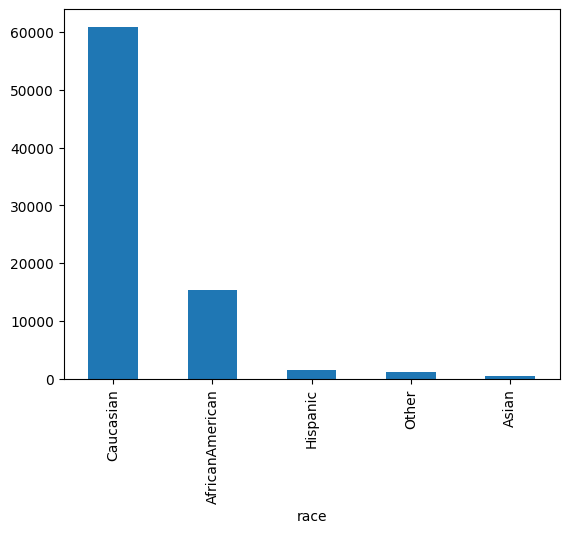

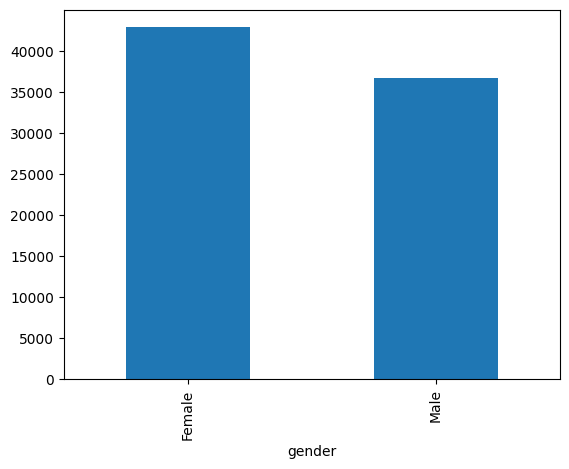

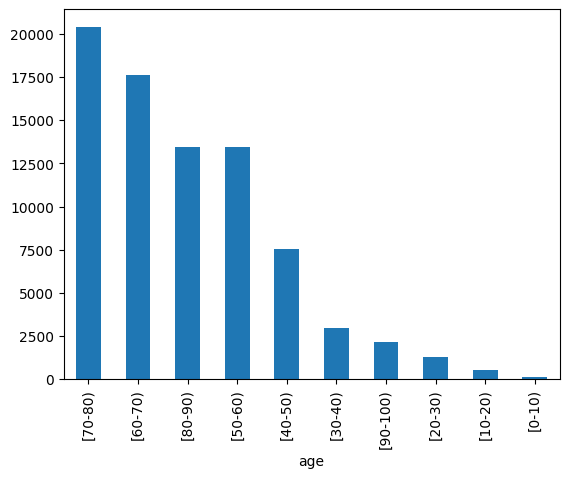

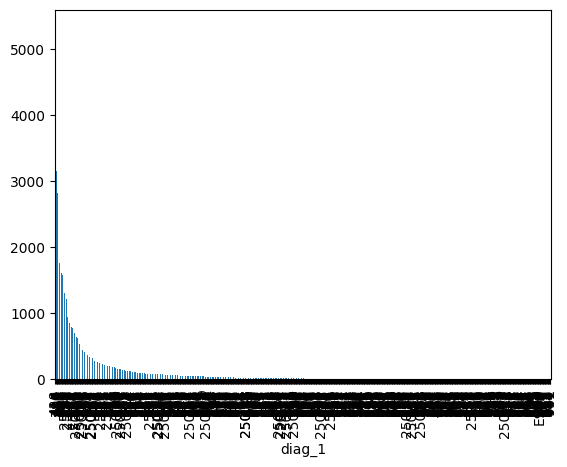

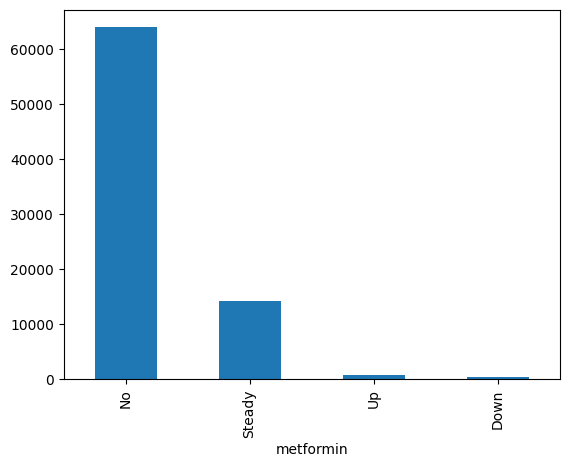

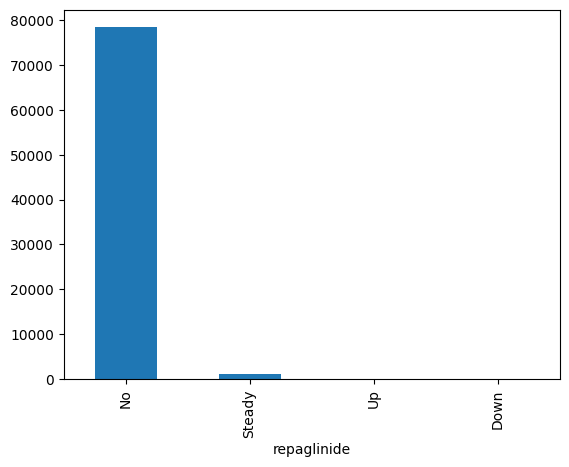

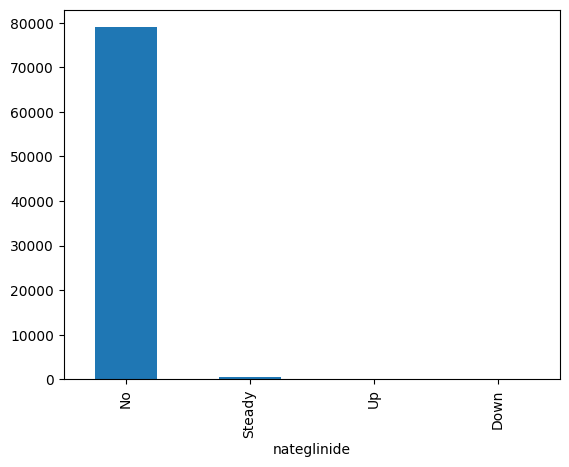

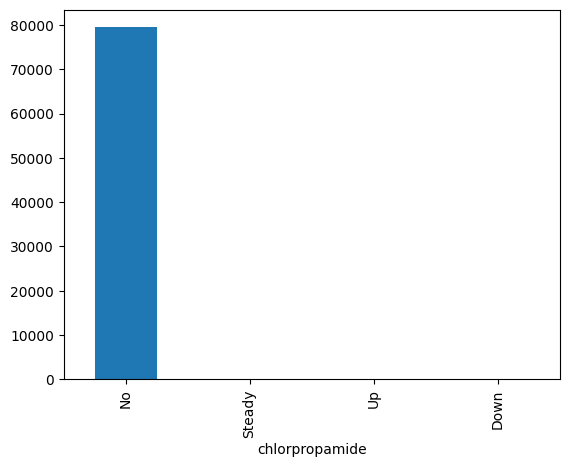

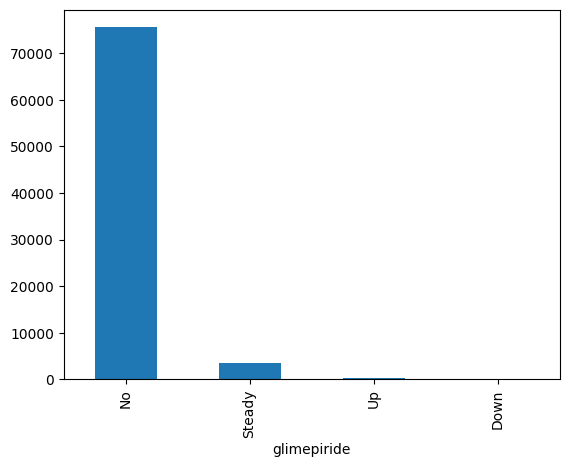

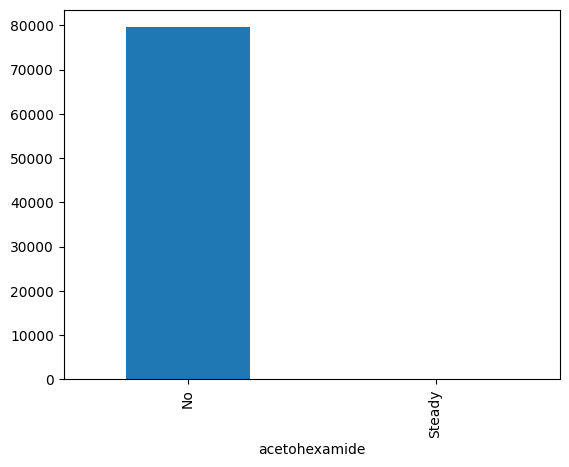

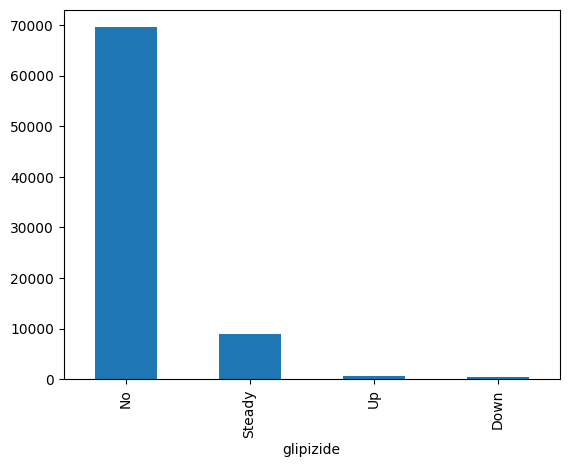

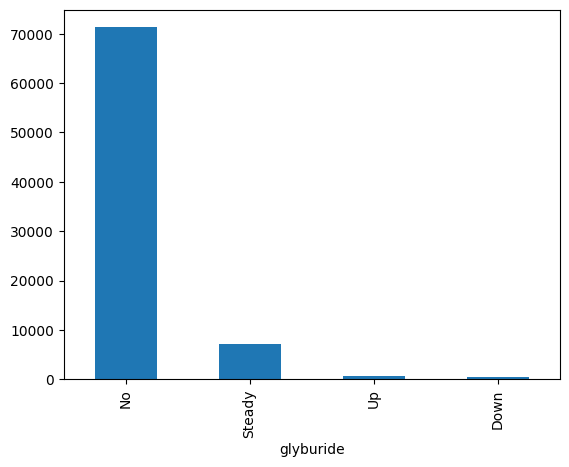

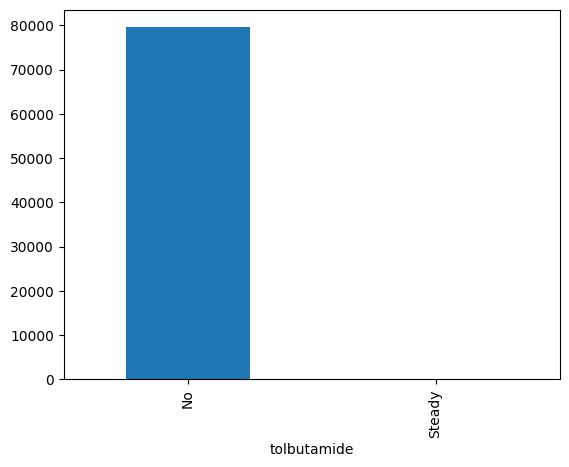

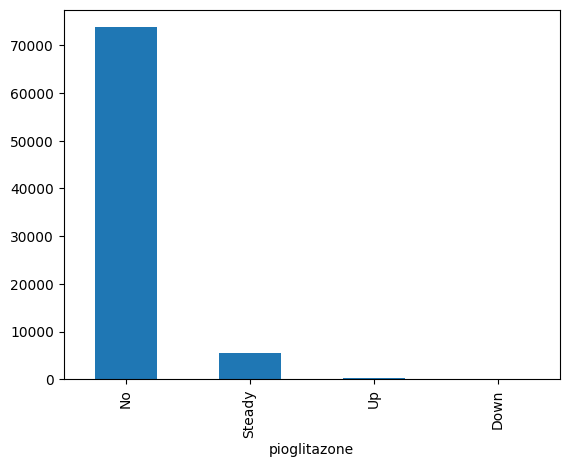

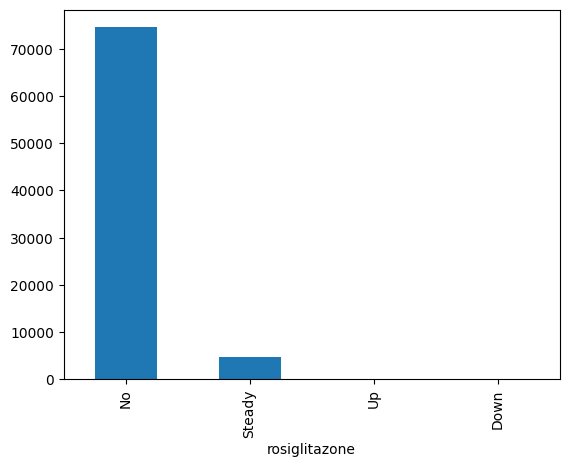

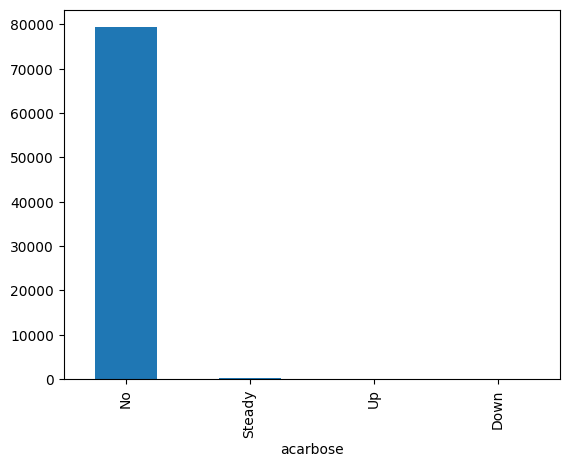

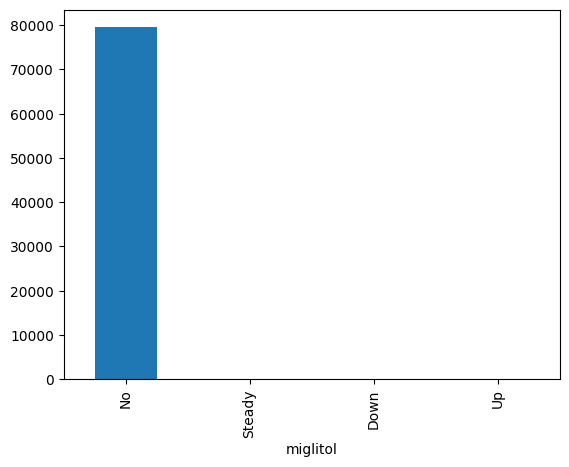

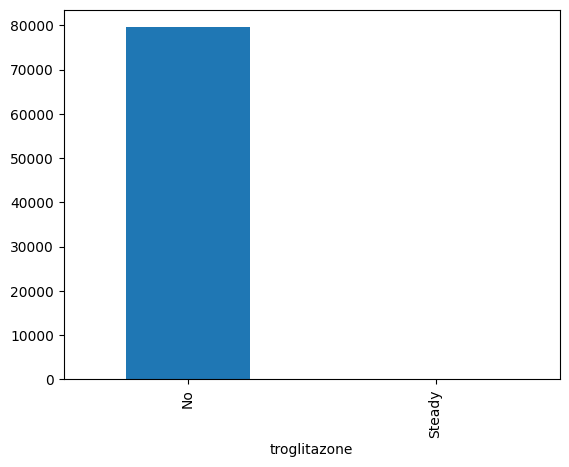

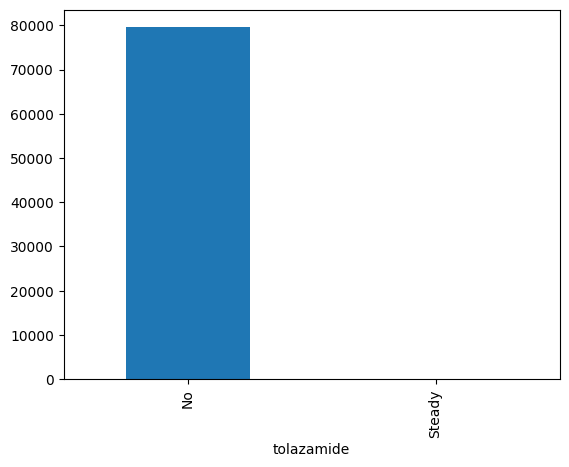

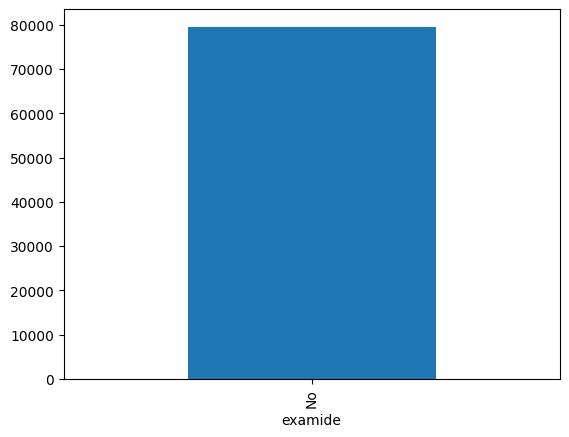

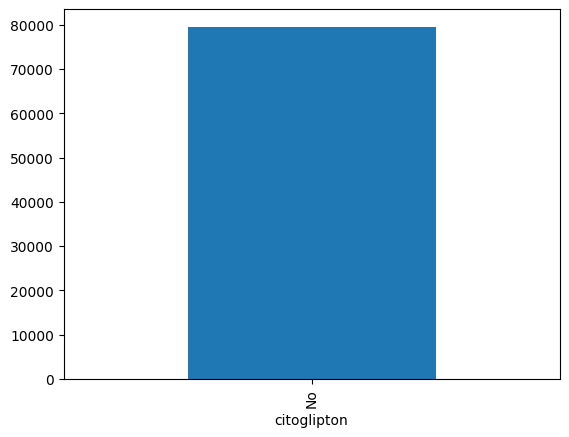

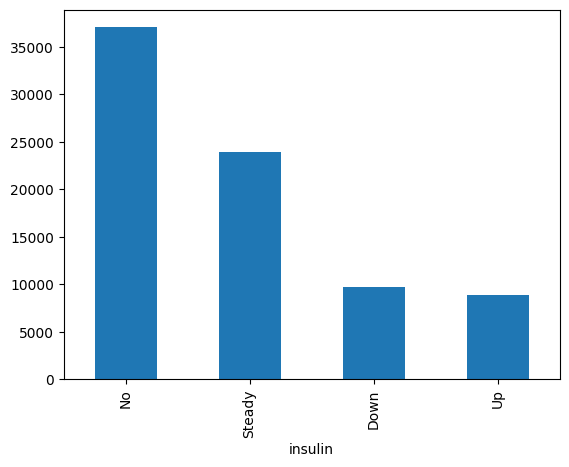

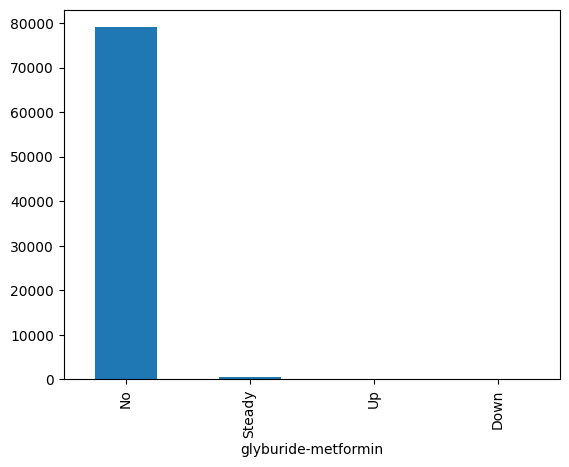

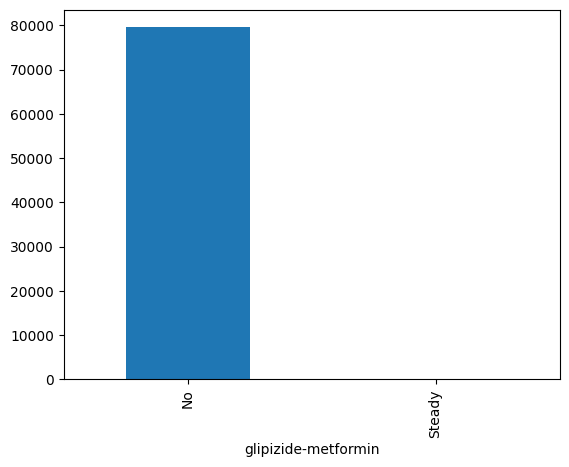

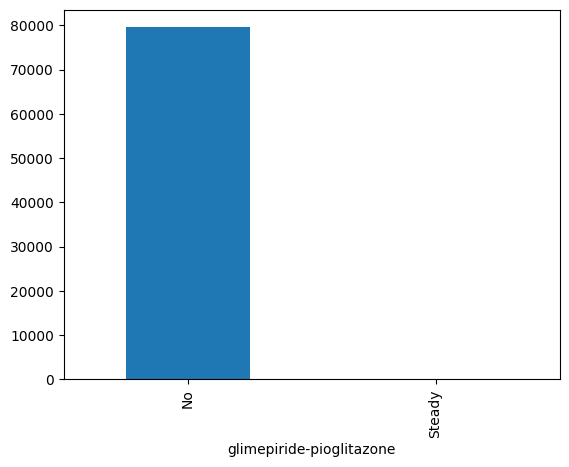

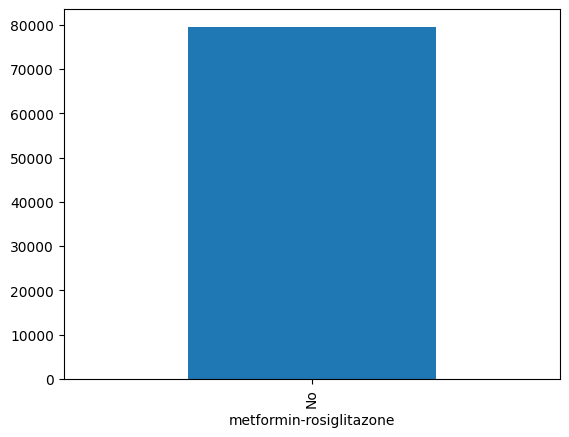

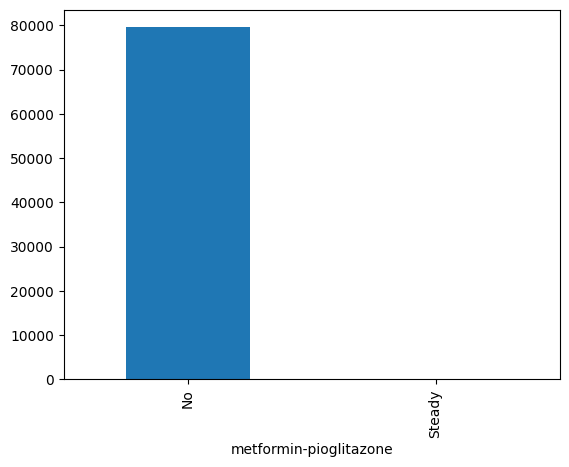

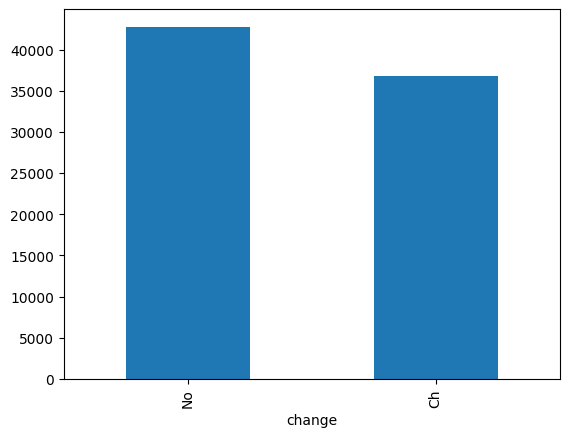

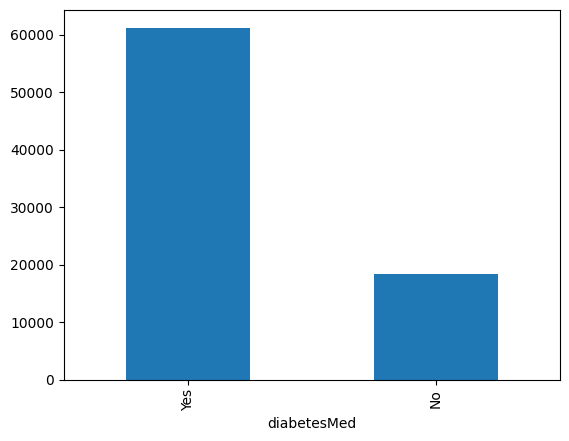

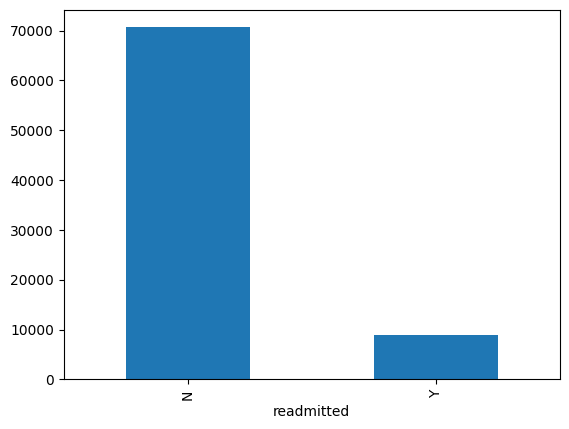

In [17]:
for col in categorical:
    categorical[col].value_counts().plot(kind='bar')
    plt.show()
    

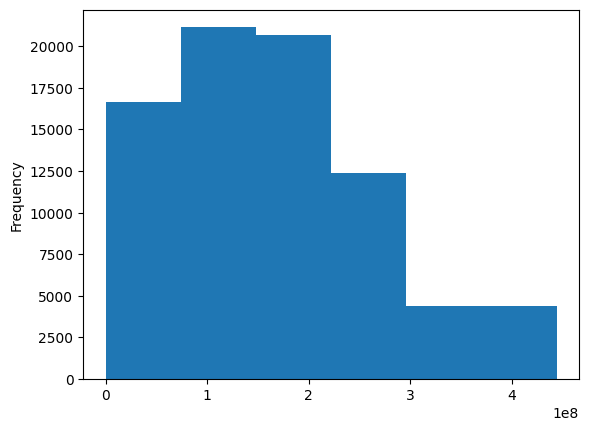

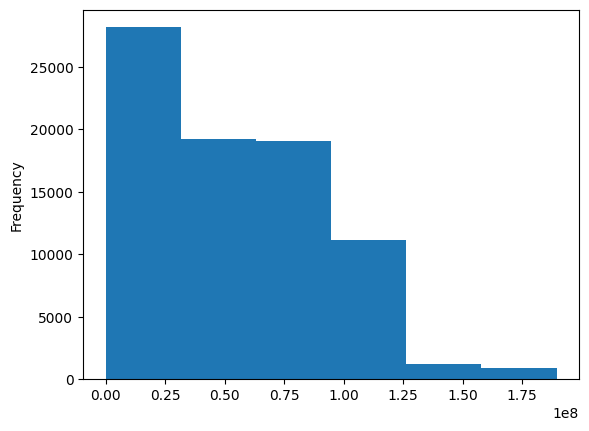

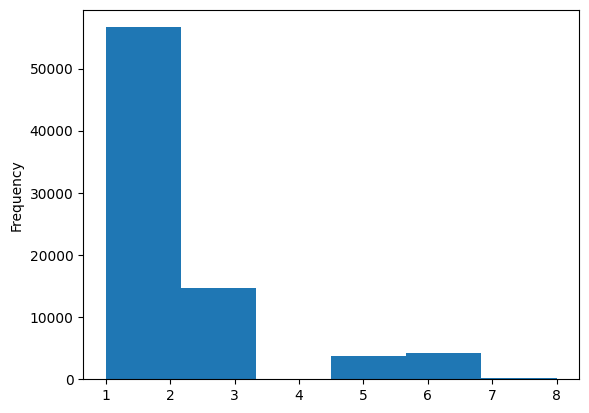

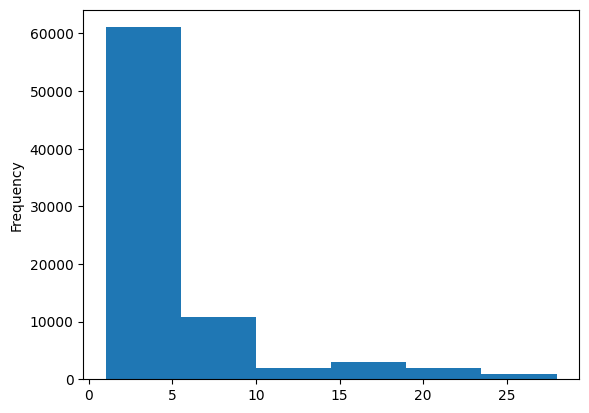

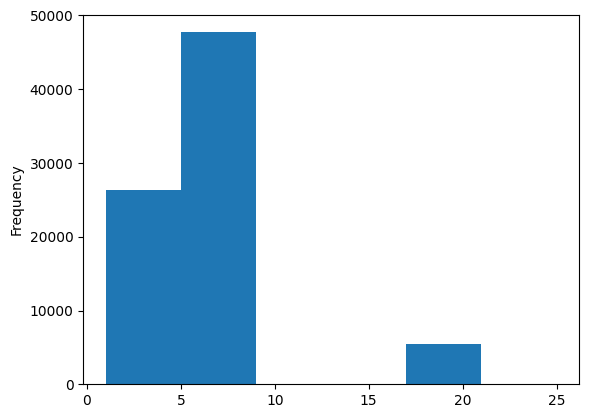

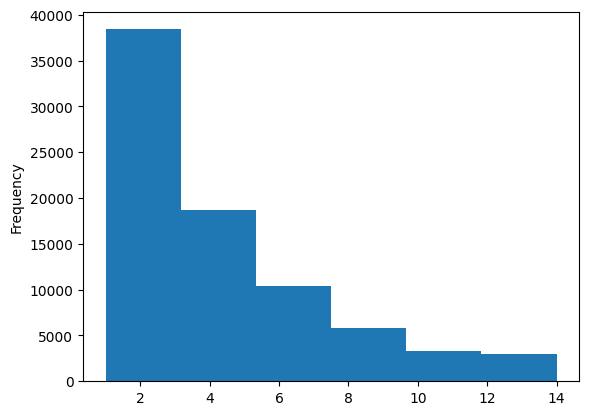

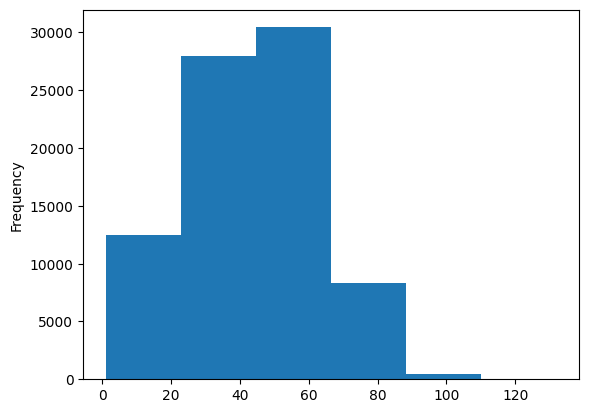

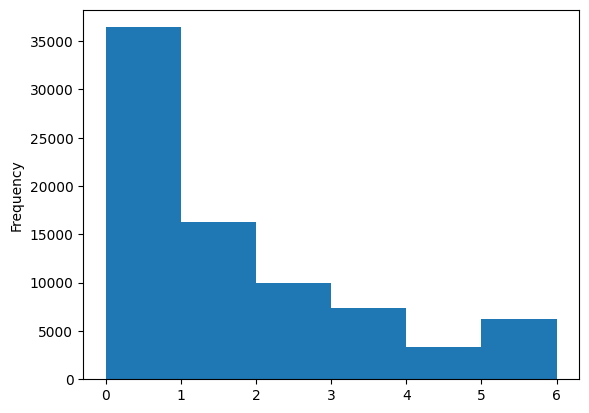

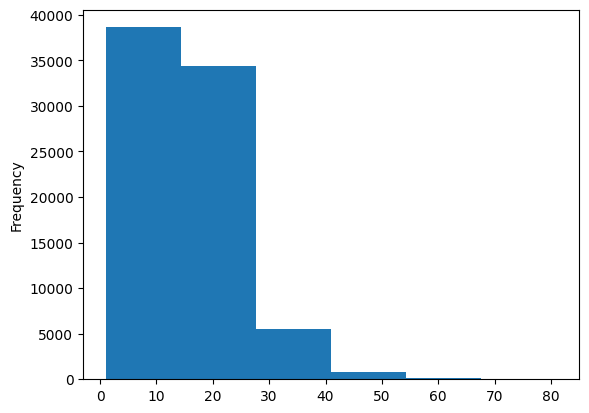

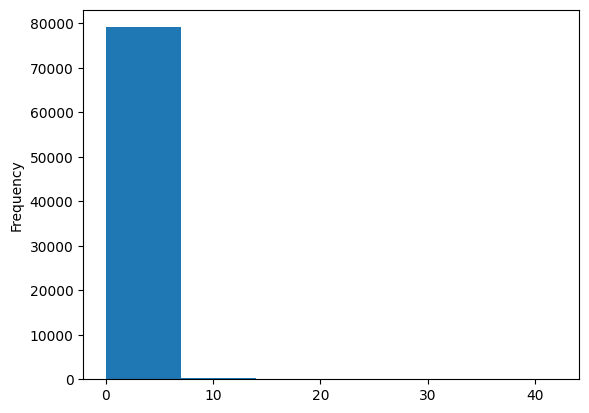

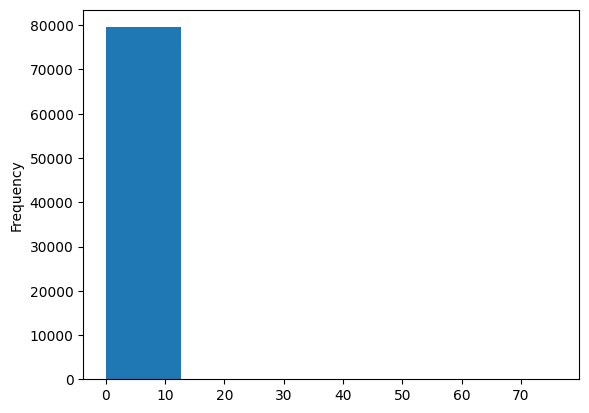

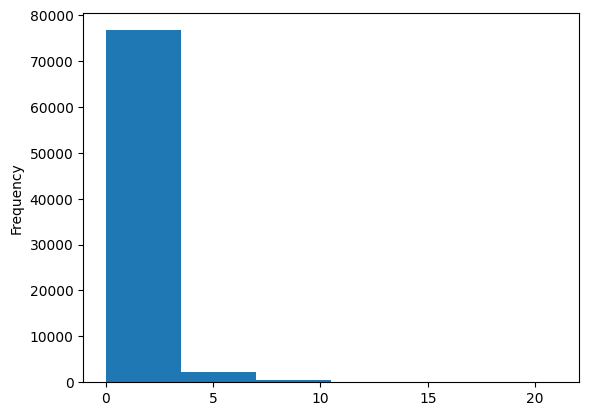

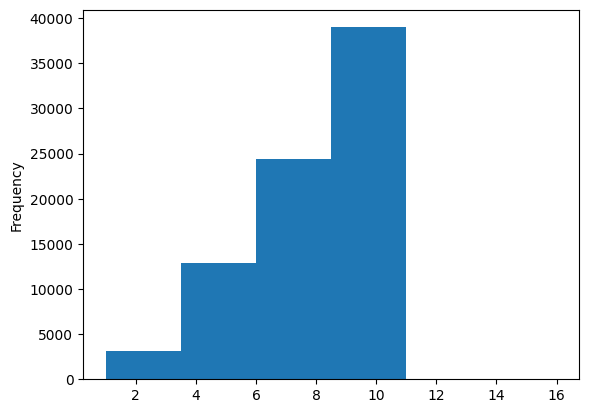

In [18]:
for col in numeric:
    numeric[col].plot.hist(bins=6)
    plt.show()

In [19]:
# Deleting the 2 columns because they have all the observations only in one category 
data.drop(['examide','citoglipton'],axis=1,inplace=True)
data.shape

(79584, 41)

In [20]:
#Making the target variable and other variables binary
data = data[data['readmitted'].isin(['Y', 'N'])]
data['readmitted'] = data['readmitted'].apply(lambda x: 0 if x == "N" else 1)
data['change'] = data['change'].apply(lambda x: 0 if x == "No" else 1)
data['gender'] = data['gender'].apply(lambda x: 0 if x == "Female" else 1)
data['diabetesMed'] = data['diabetesMed'].apply(lambda x: 0 if x == "No" else 1)
data.shape

(79584, 41)

In [21]:
# There are 3 types of visits to a hospital. 1) Inpatient 2) Outpatient 3) Emergency.
# Combining them into a single column
data['total_visits'] = data['number_outpatient'] + data['number_emergency'] + data['number_inpatient']

We have age feature which is given in bins. We have to changed it with the average value. eg: for age 0-10 we took the average age which is 5.

In [22]:
#defining a function to give average value for the age
def agecategory(x):
    
    if x == "[0-10)" :
        return 5
    elif x == "[10-20)":
        return 15
    elif x == "[20-30)":
        return 25
    elif x == "[30-40)":
        return 35
    elif x == "[40-50)":
        return 45
    elif x == "[50-60)":
        return 55
    elif x == "[60-70)":
        return 65
    elif x == "[70-80)":
        return 75
    elif x == "[80-90)":
        return 85
    elif x == "[90-100)":
        return 95
    else:
        return 0
        

In [23]:
#replacing the age bins with their average value
data['age'] = data['age'].apply(lambda x: agecategory(x))

In [24]:
data['age'][:10]

0     5
1    15
2    25
3    35
4    45
5    55
6    65
7    75
8    85
9    45
Name: age, dtype: int64

There are 23 treatments of which 2 treatments are never used by patients and we took the number of treatments the patient has undergone as a feature which will be used for analysis.

In [25]:
#It seems like there are many treatments from which a doctor would recommend the patient, lets combine all the\
#treatments into one dataframe
treatments = ['metformin' ,'repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide' ,'glipizide',\
              'glyburide', 'tolbutamide', 'pioglitazone','rosiglitazone', 'acarbose' ,'miglitol' ,'troglitazone', \
              'tolazamide', 'insulin' ,'glyburide-metformin','glipizide-metformin', \
              'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

In [26]:
print(treatments)

['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [27]:
#assigning a value of 0 if there are not undergoing treatment and assigning 1 even if they are taking \
#increasing/decreasing/steady dosage
for i in treatments:
    data[i] = data[i].apply(lambda x: 0 if x == "No" else 1)

In [28]:
#finding out total number of treatments taken by patient
data['treatments_taken'] = np.zeros((len(data['metformin'])))
for col in treatments:
    data['treatments_taken'] += data[col]

In [29]:
data.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,total_visits,treatments_taken
0,2278392,8222157,Caucasian,0,5,6,25,1,1,41,...,0,0,0,0,0,0,0,0,0,0.0
1,149190,55629189,Caucasian,0,15,1,1,7,3,59,...,0,0,0,0,0,1,1,0,0,1.0
2,64410,86047875,AfricanAmerican,0,25,1,1,7,2,11,...,0,0,0,0,0,0,1,0,3,1.0
3,500364,82442376,Caucasian,1,35,1,1,7,2,44,...,0,0,0,0,0,1,1,0,0,1.0
4,16680,42519267,Caucasian,1,45,1,1,7,1,51,...,0,0,0,0,0,1,1,0,0,2.0


In [30]:
#Based on information in https://www.hindawi.com/journals/bmri/2014/781670/tab2/.Classified diagnosis into 9 categories
#Categories[0-8]: Other,Circulatory, Respiratory,Digestive, Diabetes,Injury, Musculoskeletal,Genitourinary,Neoplasms
#defining the function to classify the numbers into one of the 8 categories

def getCategor(x):
    if 'V' in str(x) or 'E' in str(x):
        return 0
    
    x = float(x)
    
    if (x >= 390 and x <= 459) or np.floor(x) == 785:
        return 1
    elif (x >= 460 and x <= 519) or np.floor(x) == 786:
        return 2
    elif (x >= 520 and x <= 579) or np.floor(x) == 787:
        return 3
    elif np.floor(x) == 250:
        return 4
    elif x >= 800 and x <= 999:
        return 5
    elif x >= 710 and x <= 739:
        return 6
    elif (x >= 580 and x <= 629) or np.floor(x) == 788:
        return 7
    elif x >= 140 and x <= 239:
        return 8
    else:
        return 0
        

In [31]:
#changing the values into categories
data['diag_1_category'] = data['diag_1'].apply(lambda x: getCategor(x))

In [32]:
data['diag_1_category'][:10]

0    4
1    0
2    0
3    0
4    8
5    1
6    1
7    1
8    1
9    4
Name: diag_1_category, dtype: int64

In [33]:
list(data)

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'number_diagnoses',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted',
 'total_visits',
 'treatments_taken',
 'diag_1_category']

Some patients in the data have more than one encounters, we need to make sure to remove the multiple patient visits because that might cause bias in our predictions. For that reason we remove all the visits by a patient other than their first visit.

In [34]:
#Check for readmitted patients and remove all visits other than the 1st visit
patients = data['patient_nbr']
data[patients.isin(patients[patients.duplicated()])]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,total_visits,treatments_taken,diag_1_category
11,40926,85504905,Caucasian,0,45,1,3,7,7,60,...,0,0,0,0,1,1,1,1,3.0,1
23,250872,41606064,Caucasian,1,25,2,1,2,10,53,...,0,0,0,0,1,1,0,0,1.0,0
27,293058,114715242,Caucasian,1,65,2,6,2,5,37,...,0,0,0,0,0,1,0,0,1.0,2
29,325848,63023292,Caucasian,0,65,1,1,7,2,41,...,0,0,0,0,1,1,0,0,2.0,1
37,486156,86240259,Caucasian,0,75,3,5,4,9,25,...,0,0,0,0,1,1,1,2,2.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81400,443804570,33230016,Caucasian,0,75,1,22,7,8,51,...,0,0,0,0,0,1,0,0,1.0,1
81407,443842136,181593374,Caucasian,0,75,1,1,7,5,21,...,0,0,0,0,0,1,0,1,1.0,2
81410,443847782,74694222,AfricanAmerican,0,85,1,4,5,5,33,...,0,0,0,0,0,1,0,1,1.0,3
81411,443854148,41088789,Caucasian,1,75,1,1,7,1,53,...,0,0,0,0,1,1,0,1,2.0,0


In [35]:
#dropping the patients encounters other than 1st visit
data = data.drop_duplicates(subset= ['patient_nbr'], keep = 'first')
data.shape

(58521, 44)

Variables like admission_type_id, discharge_despotion_id etc does not have any intrinsic value associated with them. So we make them categorical variables.

In [36]:
# coercing the admission_type_id, discharge_disposition_id, admission_source_id diag_1_category, \
# max_glu_serum, A1Cresult into categorical since the magnitudes does not have any intrinsic value
data['admission_type_id'] = data['admission_type_id'].astype('object')
data['admission_source_id'] = data['admission_source_id'].astype('object')
data['discharge_disposition_id'] = data['discharge_disposition_id'].astype('object')
data['diag_1_category'] = data['diag_1_category'].astype('object')


Features like encounter_id, patient_nbr are for identity purpose and do not contribute towards predictions, so we get rid of them. Variables like number_outpatient, number_emergency are being used to create new variable which are being used for analysis. So we can get rid of the other variables since we got the target variable which ais going to be used for predictions.

In [37]:
# creating a list for unnecessary columns
delete_columns = ['encounter_id','patient_nbr','number_outpatient','number_emergency','number_inpatient',\
                 'metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide','glipizide'\
                  ,'glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol','troglitazone' \
                  ,'tolazamide','insulin','glyburide-metformin','glipizide-metformin','glimepiride-pioglitazone',\
                  'metformin-rosiglitazone','metformin-pioglitazone','diag_1']

In [38]:
#dropping the unnecessary columns
data.drop(delete_columns, inplace=True, axis=1)

In [39]:
data.head()

,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,change,diabetesMed,readmitted,total_visits,treatments_taken,diag_1_category
0,Caucasian,0,5,6,25,1,1,41,0,1,1,0,0,0,0,0.0,4
1,Caucasian,0,15,1,1,7,3,59,0,18,9,1,1,0,0,1.0,0
2,AfricanAmerican,0,25,1,1,7,2,11,5,13,6,0,1,0,3,1.0,0
3,Caucasian,1,35,1,1,7,2,44,1,16,7,1,1,0,0,1.0,0
4,Caucasian,1,45,1,1,7,1,51,0,8,5,1,1,0,0,2.0,8


In [40]:
#creating a list of categorical and numeric lists
categorical=data.select_dtypes(include=['object'])
numeric=data.select_dtypes(exclude=['object'])
print(categorical.columns.values)
print(numeric.columns.values)

<StringArray>
[                    'race',        'admission_type_id',
 'discharge_disposition_id',      'admission_source_id',
          'diag_1_category']
Length: 5, dtype: str
<StringArray>
[            'gender',                'age',   'time_in_hospital',
 'num_lab_procedures',     'num_procedures',    'num_medications',
   'number_diagnoses',             'change',        'diabetesMed',
         'readmitted',       'total_visits',   'treatments_taken']
Length: 12, dtype: str


C:\Users\Vijay\AppData\Local\Temp\ipykernel_43580\2544748223.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical=data.select_dtypes(include=['object'])


In [41]:
# creating dummies for all the categorical variables and deleting the original columns
nominal_columns = ['race', 'admission_type_id', 'discharge_disposition_id','admission_source_id' ,'diag_1_category']
dummy_df = pd.get_dummies(data[nominal_columns])
data = pd.concat([data, dummy_df], axis=1)
data = data.drop(nominal_columns, axis=1)

In [42]:
data.head()

,gender,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,change,diabetesMed,readmitted,...,admission_source_id_25,diag_1_category_0,diag_1_category_1,diag_1_category_2,diag_1_category_3,diag_1_category_4,diag_1_category_5,diag_1_category_6,diag_1_category_7,diag_1_category_8
0,0,5,1,41,0,1,1,0,0,0,...,False,False,False,False,False,True,False,False,False,False
1,0,15,3,59,0,18,9,1,1,0,...,False,True,False,False,False,False,False,False,False,False
2,0,25,2,11,5,13,6,0,1,0,...,False,True,False,False,False,False,False,False,False,False
3,1,35,2,44,1,16,7,1,1,0,...,False,True,False,False,False,False,False,False,False,False
4,1,45,1,51,0,8,5,1,1,0,...,False,False,False,False,False,False,False,False,False,True


In [43]:
data1 = data

In [44]:
data1

,gender,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,change,diabetesMed,readmitted,...,admission_source_id_25,diag_1_category_0,diag_1_category_1,diag_1_category_2,diag_1_category_3,diag_1_category_4,diag_1_category_5,diag_1_category_6,diag_1_category_7,diag_1_category_8
0,0,5,1,41,0,1,1,0,0,0,...,False,False,False,False,False,True,False,False,False,False
1,0,15,3,59,0,18,9,1,1,0,...,False,True,False,False,False,False,False,False,False,False
2,0,25,2,11,5,13,6,0,1,0,...,False,True,False,False,False,False,False,False,False,False
3,1,35,2,44,1,16,7,1,1,0,...,False,True,False,False,False,False,False,False,False,False
4,1,45,1,51,0,8,5,1,1,0,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81405,0,45,14,73,6,26,9,1,1,0,...,False,False,False,False,False,False,False,False,True,False
81406,0,65,2,46,6,17,9,0,1,0,...,False,False,False,False,False,False,True,False,False,False
81408,0,85,5,76,1,22,9,1,1,0,...,False,True,False,False,False,False,False,False,False,False
81409,1,75,3,51,0,16,9,1,1,0,...,False,False,False,False,False,True,False,False,False,False


In [45]:
y = data1['readmitted']

In [46]:
X = data1.drop('readmitted',axis=1)

In [47]:
X_train, X_test, Y_train, Y_test = train_test_split(X,y, test_size=0.20, random_state=42)

In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import GridSearchCV
clf = RandomForestClassifier(n_estimators=64, max_features='sqrt')
clf = clf.fit(X_train, Y_train)

In [49]:
features = pd.DataFrame()
features['feature'] = X_train.columns
features['importance'] = clf.feature_importances_
features.sort_values(by=['importance'], ascending=True, inplace=True)
features.set_index('feature', inplace=True)

There are 82 features in the model but not all the features have the predictive power. We have eliminated the features that has less than 1% importance.

<Axes: ylabel='feature'>

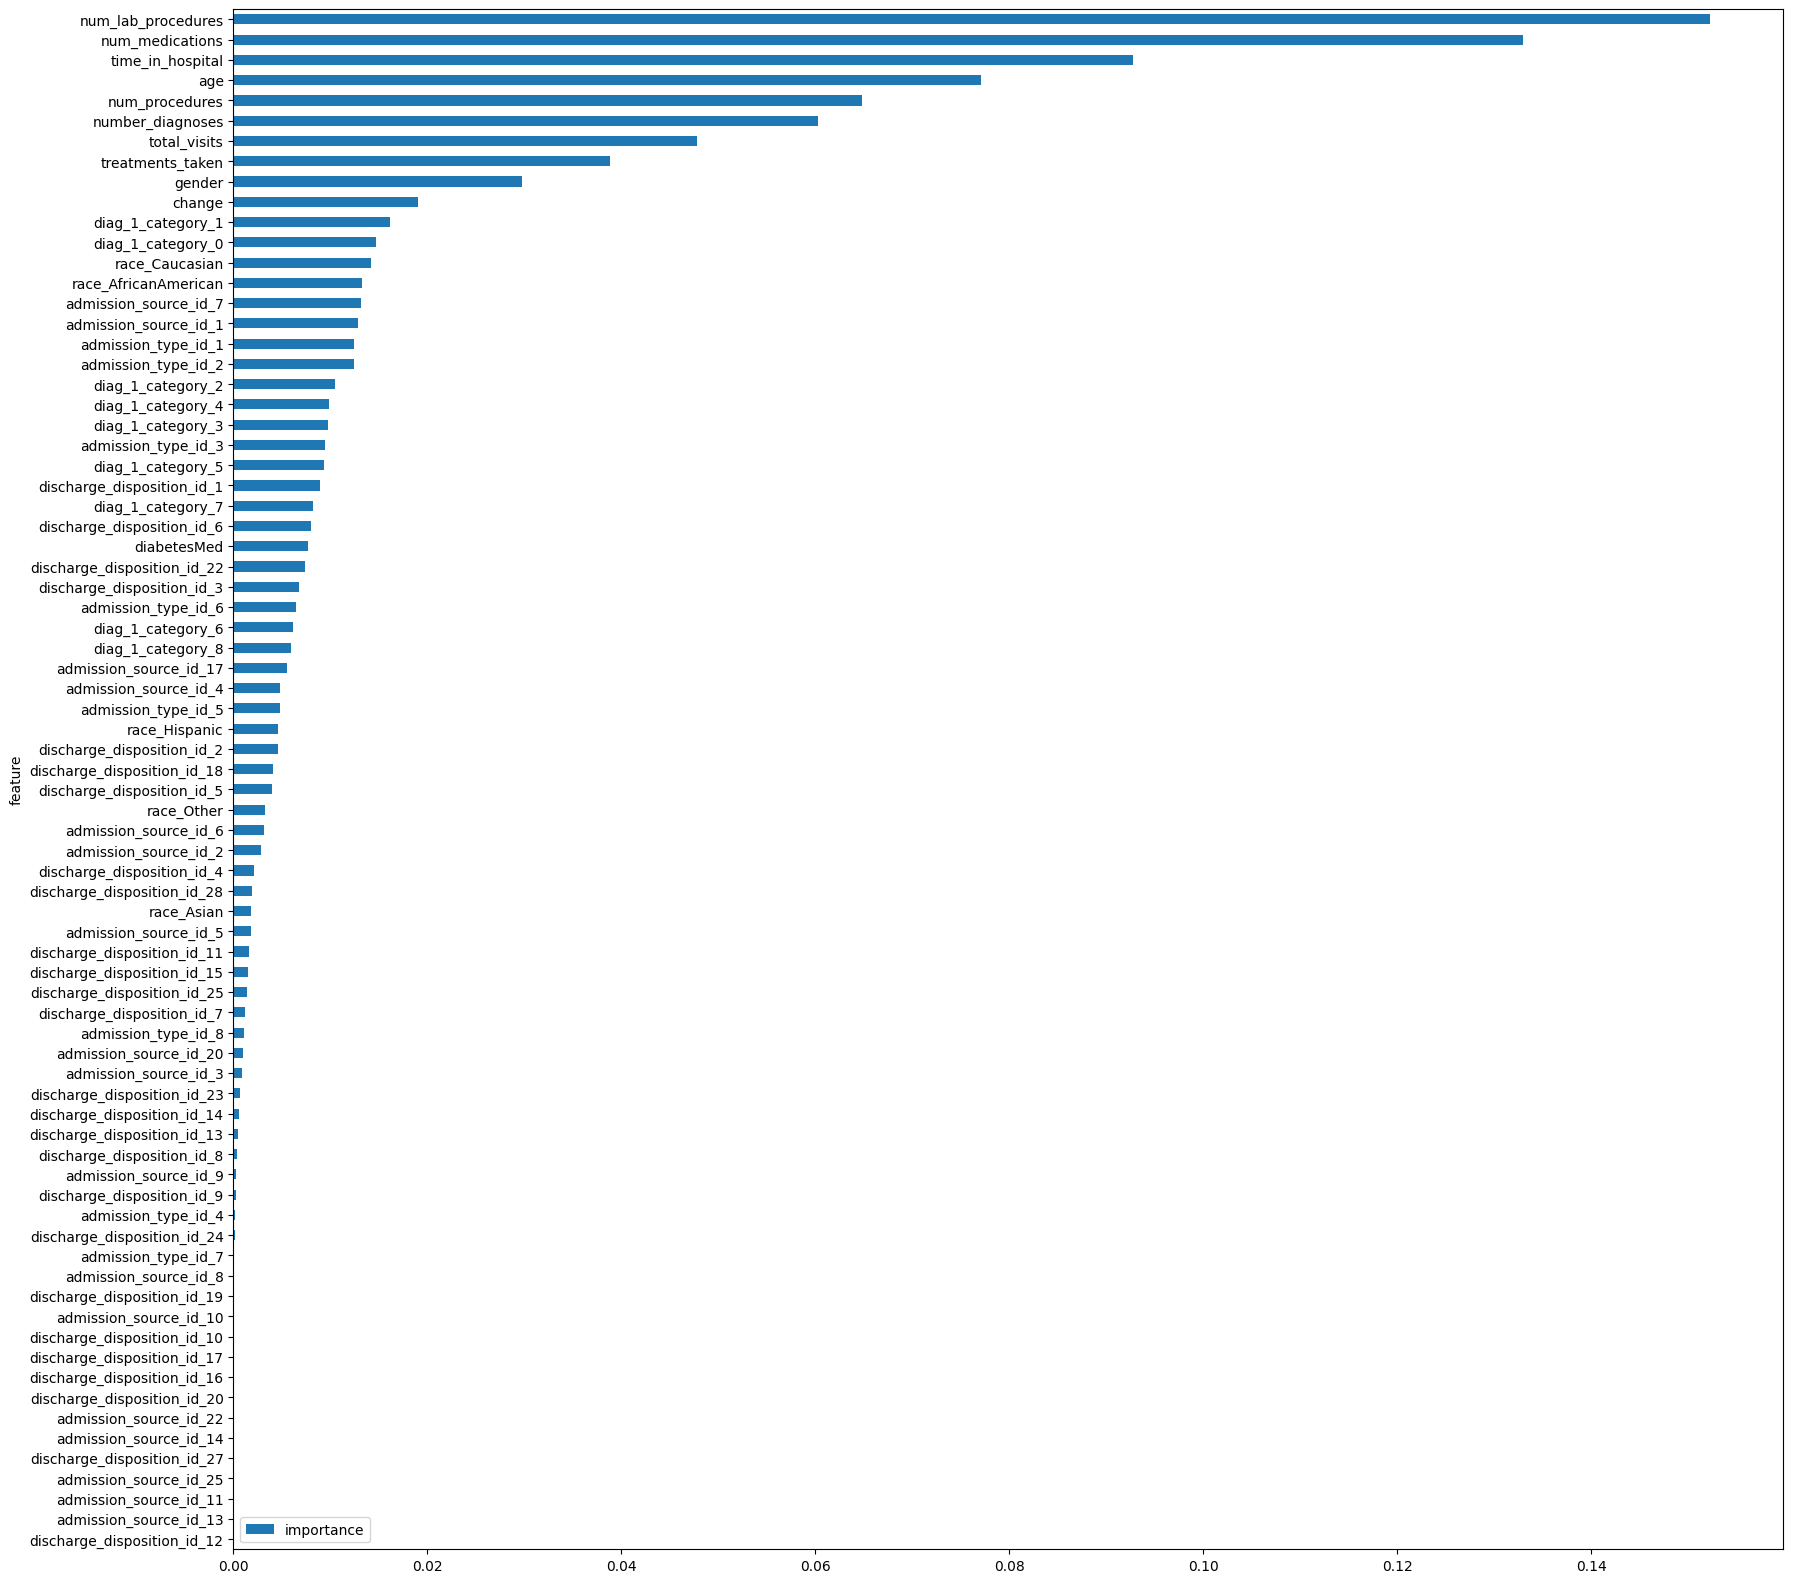

In [50]:
features.plot(kind='barh', figsize=(20, 20))

In [51]:
#deleting all the low important features starting from diag_1_category_8
low_importance_features = ['diag_1_category_8','admission_source_id_4', 'discharge_disposition_id_2','admission_source_id_17',\
      'discharge_disposition_id_18','admission_type_id_5','discharge_disposition_id_5','race_Hispanic',\
      'race_Other', 'admission_source_id_6',\
      'admission_source_id_2','discharge_disposition_id_4','admission_source_id_5', 'race_Asian', \
      'discharge_disposition_id_28','discharge_disposition_id_11','discharge_disposition_id_15',\
      'discharge_disposition_id_25','discharge_disposition_id_7', 'admission_type_id_8', 'admission_source_id_3',\
      'admission_source_id_20','discharge_disposition_id_23','discharge_disposition_id_14','discharge_disposition_id_13',\
      'discharge_disposition_id_8','discharge_disposition_id_16', 'admission_source_id_9', 'discharge_disposition_id_9','discharge_disposition_id_24',\
      'admission_type_id_4','admission_type_id_7','admission_source_id_10','discharge_disposition_id_19','discharge_disposition_id_17',\
      'admission_source_id_8','discharge_disposition_id_16','admission_source_id_25','discharge_disposition_id_10','discharge_disposition_id_20',\
      'admission_source_id_13','admission_source_id_11','admission_source_id_22','admission_source_id_14',\
      'discharge_disposition_id_27','discharge_disposition_id_12']


In [52]:
print(data1.columns.tolist())

['gender', 'age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_diagnoses', 'change', 'diabetesMed', 'readmitted', 'total_visits', 'treatments_taken', 'race_AfricanAmerican', 'race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Other', 'admission_type_id_1', 'admission_type_id_2', 'admission_type_id_3', 'admission_type_id_4', 'admission_type_id_5', 'admission_type_id_6', 'admission_type_id_7', 'admission_type_id_8', 'discharge_disposition_id_1', 'discharge_disposition_id_2', 'discharge_disposition_id_3', 'discharge_disposition_id_4', 'discharge_disposition_id_5', 'discharge_disposition_id_6', 'discharge_disposition_id_7', 'discharge_disposition_id_8', 'discharge_disposition_id_9', 'discharge_disposition_id_10', 'discharge_disposition_id_11', 'discharge_disposition_id_12', 'discharge_disposition_id_13', 'discharge_disposition_id_14', 'discharge_disposition_id_15', 'discharge_disposition_id_16', 'discharge_disposition_id_17', 'discharge_disposit

In [53]:
data_final = data1.drop(low_importance_features, axis = 1, errors='ignore')

In [54]:
y = data_final['readmitted']

In [55]:
X = data_final.drop('readmitted',axis=1)

In [56]:
X_train, X_test, Y_train, Y_test = train_test_split(X,y, test_size=0.20, random_state=42)

# Decision Tree

In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, precision_score, recall_score

In [58]:
from sklearn.model_selection import cross_val_score

performance = []
for max_depth in [2,3,5,7,10]:
    dTree = DecisionTreeClassifier(criterion='entropy', class_weight = "balanced", max_depth=max_depth)
    performance.append((max_depth, np.mean(cross_val_score(dTree, X_train, Y_train, cv = 10, scoring = "f1_micro"))))

In [59]:
print(performance)
print("The best tree size is: ") 
str(sorted(performance, key = lambda x: x[1])[-1][0])

[(2, np.float64(0.4805196801561129)), (3, np.float64(0.5048704164663225)), (5, np.float64(0.5444733912557521)), (7, np.float64(0.5650197737388213)), (10, np.float64(0.5775588209071527))]
The best tree size is: 


'10'

In [60]:
X_train

,gender,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,change,diabetesMed,total_visits,...,admission_source_id_1,admission_source_id_7,diag_1_category_0,diag_1_category_1,diag_1_category_2,diag_1_category_3,diag_1_category_4,diag_1_category_5,diag_1_category_6,diag_1_category_7
22990,1,75,3,55,1,19,6,0,0,3,...,True,False,True,False,False,False,False,False,False,False
40949,1,75,8,44,6,24,9,1,1,2,...,True,False,False,False,False,True,False,False,False,False
66248,1,65,4,68,2,13,9,0,0,0,...,False,True,False,True,False,False,False,False,False,False
12757,1,85,8,2,2,10,8,0,1,4,...,False,False,False,True,False,False,False,False,False,False
48624,0,65,5,54,0,24,8,1,1,1,...,True,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74743,1,55,2,1,0,5,9,0,0,0,...,False,True,False,False,True,False,False,False,False,False
50005,0,35,1,26,3,25,9,0,1,0,...,True,False,False,False,False,False,False,False,True,False
943,0,55,5,50,0,15,7,0,1,0,...,False,True,False,True,False,False,False,False,False,False
20752,0,75,5,65,0,14,5,0,0,0,...,False,True,False,True,False,False,False,False,False,False


In [61]:
from sklearn.model_selection import cross_val_score, KFold

dTree = DecisionTreeClassifier(criterion='entropy', class_weight='balanced', max_depth = 5)
kf = KFold(n_splits=10, shuffle=True, random_state=0)
dTree.fit(X_train, Y_train)

print("Test Results:")
y_prediction = dTree.predict(X_test)
print(classification_report(Y_test, y_prediction))

Test Results:
              precision    recall  f1-score   support

           0       0.94      0.53      0.68     10664
           1       0.12      0.64      0.20      1041

    accuracy                           0.54     11705
   macro avg       0.53      0.58      0.44     11705
weighted avg       0.86      0.54      0.63     11705



# Logistic Regression

In [62]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_normal = scaler.fit_transform(X_train)
X_test_normal = scaler.transform(X_test)

model = LogisticRegressionCV(Cs = 10, cv = 10, class_weight = "balanced")
model.fit(X_train_normal, Y_train)

c:\Users\Vijay\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\Vijay\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.w

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add a L2 penalty term (used by default);- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy ` is used.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slower in :class:`LogisticRegressionCV` because it does not handle warm-starting.- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass se

In [63]:
y_prediction = model.predict(X_test_normal)
print(classification_report(Y_test, y_prediction))

              precision    recall  f1-score   support

           0       0.94      0.66      0.77     10664
           1       0.14      0.55      0.22      1041

    accuracy                           0.65     11705
   macro avg       0.54      0.60      0.50     11705
weighted avg       0.87      0.65      0.72     11705



In [64]:
y_pred_dtc_fair = dTree.predict(X_test)
y_pred_lr_fair = model.predict(X_test_normal)

fairness_df = pd.DataFrame({
    "age": X_test["age"].reset_index(drop=True),
    "y_true": Y_test.reset_index(drop=True),
    "y_pred_dtc_fair": y_pred_dtc_fair,
    "y_pred_lr_fair": y_pred_lr_fair
})

fairness_rows = []
for age_value, age_group in fairness_df.groupby("age", sort=True):
    fairness_rows.append({
        "age": age_value,
        "actual_readmitted_count": int((age_group["y_true"] == 1).sum()),
        "decision_tree_recall_class_1": recall_score(
            age_group["y_true"],
            age_group["y_pred_dtc_fair"],
            pos_label=1,
            zero_division=0
        ),
        "logistic_regression_recall_class_1": recall_score(
            age_group["y_true"],
            age_group["y_pred_lr_fair"],
            pos_label=1,
            zero_division=0
        )
    })

fairness_by_age = pd.DataFrame(fairness_rows)
print(fairness_by_age.to_string(index=False))


 age  actual_readmitted_count  decision_tree_recall_class_1  logistic_regression_recall_class_1
   5                        0                      0.000000                            0.000000
  15                        5                      0.200000                            0.000000
  25                       16                      0.437500                            0.250000
  35                       30                      0.366667                            0.200000
  45                       85                      0.435294                            0.388235
  55                      130                      0.576923                            0.469231
  65                      269                      0.594796                            0.490706
  75                      280                      0.685714                            0.592857
  85                      201                      0.786070                            0.746269
  95                       25           

# Reading the test dataset

In [65]:
data2=pd.read_csv("test_data.csv",header=0,skiprows=0,engine='python')
ids = data2['encounter_id']
data2[ids.isin(ids[ids.duplicated()])]
data2 = data2.replace('?', np.nan )
data2 = data2.replace('Unknown/Invalid', np.nan )



In [66]:
data2.drop(['weight','payer_code','medical_specialty','diag_2', 'diag_3'],axis=1,inplace=True)
data2.dropna(inplace=True)
data2.drop(['examide','citoglipton'],axis=1,inplace=True)
data2['change'] = data2['change'].apply(lambda x: 0 if x == "No" else 1)
data2['gender'] = data2['gender'].apply(lambda x: 0 if x == "Female" else 1)
data2['diabetesMed'] = data2['diabetesMed'].apply(lambda x: 0 if x == "No" else 1)
data2['total_visits'] = data2['number_outpatient'] + data2['number_emergency'] + data2['number_inpatient']
def agecategory(x):
    
    if x == "[0-10)" :
        return 5
    elif x == "[10-20)":
        return 15
    elif x == "[20-30)":
        return 25
    elif x == "[30-40)":
        return 35
    elif x == "[40-50)":
        return 45
    elif x == "[50-60)":
        return 55
    elif x == "[60-70)":
        return 65
    elif x == "[70-80)":
        return 75
    elif x == "[80-90)":
        return 85
    elif x == "[90-100)":
        return 95
    else:
        return 0
data2['age'] = data2['age'].apply(lambda x: agecategory(x))
treatments = ['metformin' ,'repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide' ,'glipizide',\
              'glyburide', 'tolbutamide', 'pioglitazone','rosiglitazone', 'acarbose' ,'miglitol' ,'troglitazone', \
              'tolazamide', 'insulin' ,'glyburide-metformin','glipizide-metformin', \
              'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
for i in treatments:
    data2[i] = data2[i].apply(lambda x: 0 if x == "No" else 1)
data2['treatments_taken'] = np.zeros((len(data2['metformin'])))
for col in treatments:
    data2['treatments_taken'] += data2[col]
    

def getCategor(x):
    if 'V' in str(x) or 'E' in str(x):
        return 0
    
    x = float(x)
    
    if (x >= 390 and x <= 459) or np.floor(x) == 785:
        return 1
    elif (x >= 460 and x <= 519) or np.floor(x) == 786:
        return 2
    elif (x >= 520 and x <= 579) or np.floor(x) == 787:
        return 3
    elif np.floor(x) == 250:
        return 4
    elif x >= 800 and x <= 999:
        return 5
    elif x >= 710 and x <= 739:
        return 6
    elif (x >= 580 and x <= 629) or np.floor(x) == 788:
        return 7
    elif x >= 140 and x <= 239:
        return 8
    else:
        return 0

data2['diag_1_category'] = data2['diag_1'].apply(lambda x: getCategor(x))

patients = data2['patient_nbr']
data2[patients.isin(patients[patients.duplicated()])]
data2 = data2.drop_duplicates(subset= ['patient_nbr'], keep = 'first')
data2 = data2.reset_index(drop=True)
data2['admission_type_id'] = data2['admission_type_id'].astype('object')
data2['admission_source_id'] = data2['admission_source_id'].astype('object')
data2['discharge_disposition_id'] = data2['discharge_disposition_id'].astype('object')
data2['diag_1_category'] = data2['diag_1_category'].astype('object')

delete_columns = ['patient_nbr','number_outpatient','number_emergency','number_inpatient',\
                 'metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide','glipizide'\
                  ,'glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol','troglitazone' \
                  ,'tolazamide','insulin','glyburide-metformin','glipizide-metformin','glimepiride-pioglitazone',\
                  'metformin-rosiglitazone','metformin-pioglitazone','diag_1']

data2.drop(delete_columns, inplace=True, axis=1)

categorical=data2.select_dtypes(include=['object'])
numeric=data2.select_dtypes(exclude=['object'])

nominal_columns = ['race', 'admission_type_id', 'discharge_disposition_id','admission_source_id' ,'diag_1_category']
dummy_df = pd.get_dummies(data2[nominal_columns])
data2 = pd.concat([data2, dummy_df], axis=1)
data2 = data2.drop(nominal_columns, axis=1)

low_importance_features = ['diag_1_category_8','admission_source_id_4', 'discharge_disposition_id_2','admission_source_id_17',\
      'discharge_disposition_id_18','admission_type_id_5','discharge_disposition_id_5','race_Hispanic',\
      'race_Other', 'admission_source_id_6',\
      'admission_source_id_2','discharge_disposition_id_4','admission_source_id_5', 'race_Asian', \
      'discharge_disposition_id_28','discharge_disposition_id_11','discharge_disposition_id_15',\
      'discharge_disposition_id_25','discharge_disposition_id_7', 'admission_type_id_8', 'admission_source_id_3',\
      'admission_source_id_20','discharge_disposition_id_23','discharge_disposition_id_14','discharge_disposition_id_13',\
      'discharge_disposition_id_8', 'admission_source_id_9', 'discharge_disposition_id_9','discharge_disposition_id_24',\
      'admission_type_id_4','admission_type_id_7','discharge_disposition_id_19','discharge_disposition_id_17',\
      'admission_source_id_8','discharge_disposition_id_10',\
      'admission_source_id_22','admission_source_id_14',\
      'discharge_disposition_id_27']


data2 = data2.drop(low_importance_features, axis=1, errors='ignore')

C:\Users\Vijay\AppData\Local\Temp\ipykernel_43580\120988211.py:88: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical=data2.select_dtypes(include=['object'])


In [67]:
data2[0:3]

,encounter_id,gender,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,max_glu_serum,A1Cresult,...,discharge_disposition_id_3,discharge_disposition_id_6,admission_source_id_1,admission_source_id_7,diag_1_category_0,diag_1_category_1,diag_1_category_2,diag_1_category_3,diag_1_category_4,diag_1_category_7
0,4804968,0,55,2,61,0,5,5,>300,>8,...,False,False,False,True,True,False,False,False,False,False
1,6479016,1,85,7,105,3,16,5,>300,>7,...,False,False,False,True,False,True,False,False,False,False
2,7296540,0,55,2,66,0,3,3,Norm,>7,...,False,False,False,True,False,False,False,False,True,False


In [68]:
data2new= data2.iloc[:,1:35] 

In [69]:
#predicting using Decision Tree Classifier
data2new = data2new.reindex(columns=X_train.columns, fill_value=0)
y_prediction_DTC = dTree.predict(data2new)

In [70]:
data2new = data2new.reset_index(drop=True)

In [71]:
print(data2new.isnull().sum())

gender                         0
age                            0
time_in_hospital               0
num_lab_procedures             0
num_procedures                 0
num_medications                0
number_diagnoses               0
change                         0
diabetesMed                    0
total_visits                   0
treatments_taken               0
race_AfricanAmerican           0
race_Caucasian                 0
admission_type_id_1            0
admission_type_id_2            0
admission_type_id_3            0
admission_type_id_6            0
discharge_disposition_id_1     0
discharge_disposition_id_3     0
discharge_disposition_id_6     0
discharge_disposition_id_22    0
admission_source_id_1          0
admission_source_id_7          0
diag_1_category_0              0
diag_1_category_1              0
diag_1_category_2              0
diag_1_category_3              0
diag_1_category_4              0
diag_1_category_5              0
diag_1_category_6              0
diag_1_cat

In [72]:
#predicting using logistic regression classifier
data2_scalar = scaler.transform(data2new)
y_prediction_LRC = model.predict(data2_scalar)

In [73]:
predicted_probability = model.predict_proba(data2_scalar)

In [74]:
predicted_probability = pd.DataFrame(predicted_probability)


In [75]:
data2['y_prediction_LRC'] = pd.DataFrame(y_prediction_LRC)


In [76]:
data2['y_prediction_DTC'] = pd.DataFrame(y_prediction_DTC)[0]

In [77]:
data2['predicted_probability_LR_0'] = pd.DataFrame(predicted_probability)[0]

In [78]:
data2['predicted_probability_LR_1'] = pd.DataFrame(predicted_probability)[1]

In [79]:
predicted_probability_decisiontree = dTree.predict_proba(data2new)
data2['predicted_probability_decisiontree_0'] = pd.DataFrame(predicted_probability_decisiontree)[0]
data2['predicted_probability_decisiontree_1'] = pd.DataFrame(predicted_probability_decisiontree)[1]

In [80]:
data2[0:3]

,encounter_id,gender,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,max_glu_serum,A1Cresult,...,diag_1_category_2,diag_1_category_3,diag_1_category_4,diag_1_category_7,y_prediction_LRC,y_prediction_DTC,predicted_probability_LR_0,predicted_probability_LR_1,predicted_probability_decisiontree_0,predicted_probability_decisiontree_1
0,4804968,0,55,2,61,0,5,5,>300,>8,...,False,False,False,False,0,0,0.558996,0.441004,0.702513,0.297487
1,6479016,1,85,7,105,3,16,5,>300,>7,...,False,False,False,False,1,0,0.458183,0.541817,0.523610,0.476390
2,7296540,0,55,2,66,0,3,3,Norm,>7,...,False,False,True,False,0,0,0.558276,0.441724,0.702513,0.297487


predicted_probability_LR_0 = Predicted probability using Logistic Regression Classification for 0 

predicted_probability_LR_1 = Predicted probability using Logistic Regression Classification for 1 

y_prediction_LRC = Predicted readmission using Logistic Regression Classification. 

predicted_probability_decisiontree_0 = Predicted probability using Decision Tree Classification for 0 

predicted_probability_decisiontree_1 = Predicted probability using Decision Tree Classification for 1 

y_prediction_DTC = Predicted readmission using Decision Tree Classification.

In [81]:
prediction=data2[['encounter_id','predicted_probability_LR_0','predicted_probability_LR_1', \
                  'y_prediction_LRC','predicted_probability_decisiontree_0','predicted_probability_decisiontree_1',\
                  'y_prediction_DTC']]

In [82]:
prediction[0:4]

,encounter_id,predicted_probability_LR_0,predicted_probability_LR_1,y_prediction_LRC,predicted_probability_decisiontree_0,predicted_probability_decisiontree_1,y_prediction_DTC
0,4804968,0.558996,0.441004,0,0.702513,0.297487,0
1,6479016,0.458183,0.541817,1,0.523610,0.476390,0
2,7296540,0.558276,0.441724,0,0.702513,0.297487,0
3,9030192,0.553280,0.446720,0,0.702513,0.297487,0


In [83]:
prediction.to_csv("prediction.csv")

In [84]:
print(X_train.shape)
print(X_test.shape)
print(data_final.columns.tolist())
print(y_prediction[:5])
print(y_prediction_DTC[:5])

(46816, 31)
(11705, 31)
['gender', 'age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_diagnoses', 'change', 'diabetesMed', 'readmitted', 'total_visits', 'treatments_taken', 'race_AfricanAmerican', 'race_Caucasian', 'admission_type_id_1', 'admission_type_id_2', 'admission_type_id_3', 'admission_type_id_6', 'discharge_disposition_id_1', 'discharge_disposition_id_3', 'discharge_disposition_id_6', 'discharge_disposition_id_22', 'admission_source_id_1', 'admission_source_id_7', 'diag_1_category_0', 'diag_1_category_1', 'diag_1_category_2', 'diag_1_category_3', 'diag_1_category_4', 'diag_1_category_5', 'diag_1_category_6', 'diag_1_category_7']
[1 0 0 0 1]
[0 0 0 0 1]
